# Analisis Persepsi Publik terhadap Dampak Kecerdasan Buatan dalam Pendidikan di Indonesia
### Studi Unsupervised Learning atas Komentar YouTube

**Tujuan:** mengetahui pendapat publik mengenai dampak AI dalam pendidikan di Indonesia, melalui scraping komentar YouTube dan pemodelan unsupervised learning (clustering & topic extraction).

**Struktur notebook ini mengikuti poin penugasan:**
- **(a)** Pre-processing data & text representation (≥2 pendekatan)
- **(b)** Clustering: uji beberapa k & representasi, perbandingan silhouette score
- **(c)** Persona analysis hasil clustering
- **(d)** Topic extraction (LDA & NMF) + penjelasan metode
- **(e)** Persona analysis topic extraction + perbandingan dengan clustering
- **(f)** Ringkasan seluruh step dan proses

> **Versi ini sudah divalidasi dengan menjalankan seluruh pipeline (preprocessing -> representation -> clustering) secara nyata pada dataset asli (`dataset_ai_pendidikan_indo_youtube.csv`, 3518 baris mentah), dengan perbaikan kritis pada fungsi cleaning (lihat catatan di Bagian a.3) yang terbukti meningkatkan kualitas tokenisasi.**

---


## 0. Setup & Import Library

In [1]:
!pip install pandas numpy nltk Sastrawi scikit-learn gensim google-api-python-client emoji langdetect deep-translator -q

import pandas as pd
import numpy as np
import re
import string
from collections import Counter

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
from sklearn.decomposition import LatentDirichletAllocation, NMF, PCA

from gensim.models import Word2Vec

import matplotlib.pyplot as plt
import emoji
import unicodedata

import warnings
warnings.filterwarnings("ignore")

print("Semua library berhasil dimuat.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 14.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 2.2 MB/s eta 0:00:00
Semua library berhasil dimuat.


## 1. Data Collection: Scraping Komentar YouTube

Komentar dikumpulkan dari 13 video YouTube yang membahas topik "AI dalam pendidikan di Indonesia" menggunakan **YouTube Data API v3**.

> **Catatan:** kode scraping didokumentasikan lengkap di bawah namun **tidak dijalankan otomatis** (API key tidak boleh ter-expose, dan data hasil scraping sudah tersedia di `dataset_ai_pendidikan_indo_youtube.csv`). Untuk scraping ulang: set `RUN_SCRAPING = True` dan isi API key Anda sendiri.

In [ ]:
RUN_SCRAPING = False

if RUN_SCRAPING:
    from googleapiclient.discovery import build

    API_KEY = "ISI_API_KEY_ANDA_DI_SINI"
    youtube = build("youtube", "v3", developerKey=API_KEY)

    def extract_video_id(url):
        pattern = r"(?:v=|shorts\/)([0-9A-Za-z_-]{11}).*"
        result = re.search(pattern, url)
        return result.group(1) if result else None

    video_urls = [
        "https://www.youtube.com/watch?v=9H8yqvCY4vk",
        "https://www.youtube.com/watch?v=Mqn0yLrxjpU",
        "https://www.youtube.com/shorts/s4YpJF3Ahrk",
        "https://www.youtube.com/watch?v=Zr5a1C5UjiA",
        "https://www.youtube.com/watch?v=gzJCpqZDx8I",
        "https://www.youtube.com/watch?v=g_gRHW4SJtI",
        "https://www.youtube.com/watch?v=GwEjuhpo26o",
        "https://www.youtube.com/watch?v=YSMuusyVR14",
        "https://www.youtube.com/watch?v=GK7VsV3DEwk",
        "https://www.youtube.com/watch?v=J4UUQvi3FBY",
        "https://www.youtube.com/shorts/_EhnO1yRzAw",
        "https://www.youtube.com/watch?v=K_-t9aoE0dM",
        "https://www.youtube.com/watch?v=aey4xkrz7zE",
    ]
    video_ids = [extract_video_id(u) for u in video_urls]
    video_ids = [v for v in video_ids if v is not None]
    print("Jumlah video:", len(video_ids))

    def scrape_comments(video_id, max_comments=1000):
        comments = []
        request = youtube.commentThreads().list(
            part="snippet", videoId=video_id, maxResults=100, textFormat="plainText",
        )
        response = request.execute()
        while response and len(comments) < max_comments:
            for item in response["items"]:
                c = item["snippet"]["topLevelComment"]["snippet"]
                comments.append({
                    "author": c["authorDisplayName"], "comment": c["textDisplay"],
                    "like": c["likeCount"], "published": c["publishedAt"],
                })
            if "nextPageToken" in response:
                request = youtube.commentThreads().list(
                    part="snippet", videoId=video_id, pageToken=response["nextPageToken"],
                    maxResults=100, textFormat="plainText",
                )
                response = request.execute()
            else:
                break
        return pd.DataFrame(comments)

    all_comments = []
    for vid in video_ids:
        temp = scrape_comments(vid, max_comments=1000)
        temp["video_id"] = vid
        all_comments.append(temp)
        print(f"  Video {vid}: {len(temp)} komentar")

    final_dataset = pd.concat(all_comments, ignore_index=True)
    final_dataset.to_csv("dataset_ai_pendidikan_indo_youtube.csv", index=False)
    print(f"Total komentar mentah: {final_dataset.shape}")
else:
    print("RUN_SCRAPING=False -- data dimuat dari CSV pada sel berikutnya.")

### 1.2 Memuat Data Hasil Scraping

In [2]:
final_dataset = pd.read_csv("dataset_ai_pendidikan_indo_youtube.csv")
print("Dataset mentah dimuat:", final_dataset.shape)
print("Jumlah video unik:", final_dataset["video_id"].nunique())
print("\nDistribusi komentar per video:")
print(final_dataset["video_id"].value_counts())
final_dataset.head()

Dataset mentah dimuat: (3518, 5)
Jumlah video unik: 13

Distribusi komentar per video:
video_id
GwEjuhpo26o    1000
aey4xkrz7zE     881
J4UUQvi3FBY     442
_EhnO1yRzAw     399
9H8yqvCY4vk     234
YSMuusyVR14     168
s4YpJF3Ahrk     141
g_gRHW4SJtI      81
K_-t9aoE0dM      56
gzJCpqZDx8I      45
GK7VsV3DEwk      33
Zr5a1C5UjiA      26
Mqn0yLrxjpU      12
Name: count, dtype: int64


,author,comment,like,published,video_id
0,@ANDRIRIRI,"bahkn bikin buku pun bisa pakai ai,dari cover ...",1,2026-06-20T14:45:18Z,9H8yqvCY4vk
1,@AdelioHizkia,satu hal kecil yang membuktikan bahwa AI meman...,1,2026-06-18T00:45:38Z,9H8yqvCY4vk
2,@charddaniels,Gw pake ai cuma buat ngecek ide Dan lebih bert...,0,2026-06-17T14:52:14Z,9H8yqvCY4vk
3,@BrianAn-f3n,"Ngakak bg, sistem pendidikan kita memang di de...",0,2026-06-16T21:27:33Z,9H8yqvCY4vk
4,@AgungBhakti-hn8ps,"gue pakai ai buat uji,simulasi dan verifikasi ...",0,2026-06-16T08:06:24Z,9H8yqvCY4vk


## Bagian (a): Pre-processing Data dan Text Representation

Pre-processing dilakukan melalui beberapa tahap berurutan, divalidasi langsung pada dataset asli (3518 baris mentah):
1. Cleaning dasar (dedup, hapus kosong)
2. Deteksi & pembersihan spam (termasuk yang disamarkan unicode/leetspeak)
3. Cleaning teks & normalisasi slang
4. Deteksi bahasa & translasi (~35% komentar berbahasa Inggris)
5. Tokenisasi, stopword removal, stemming
6. Text representation: Bag-of-Words, TF-IDF, Word2Vec (3 pendekatan)

### (a).1 Cleaning Dasar: Duplikat & Komentar Kosong

In [3]:
df = final_dataset.copy()

df = df[df["comment"].notnull()]
df = df[df["comment"].astype(str).str.strip() != ""]
df = df.drop_duplicates(subset=["comment"])
df.reset_index(drop=True, inplace=True)

print("Jumlah komentar setelah dedup & filter kosong:", df.shape)

Jumlah komentar setelah dedup & filter kosong: (3399, 5)


### (a).2 Deteksi & Pembersihan Spam

Komentar YouTube rawan disusupi spam judi online, disamarkan dengan unicode alternatif (`ＰＵＬＡＵＷＩＮ`, `𝘗𝘜𝘓𝘈𝘶𝘞𝘐𝘕`), leetspeak (`s3makin`), atau spasi disisip antar huruf (`P U L A U W I N`). Deteksi dilakukan dengan normalisasi unicode + leetspeak sebelum pencocokan kata kunci.

In [4]:
def normalize_for_spam_detection(text):
    text = str(text)
    text = unicodedata.normalize("NFKD", text)
    text = "".join(c for c in text if not unicodedata.combining(c))
    fullwidth_map = str.maketrans(
        "".join(chr(0xFF01 + i) for i in range(58)),
        "".join(chr(0x21 + i) for i in range(58))
    )
    text = text.translate(fullwidth_map)
    text = text.lower()
    text = re.sub(r'(?<=\b\w)\s+(?=\w\b)', '', text)
    leet_map = {"0": "o", "1": "i", "3": "e", "4": "a", "5": "s", "7": "t", "8": "b", "@": "a", "$": "s"}
    text = "".join(leet_map.get(ch, ch) for ch in text)
    return re.sub(r"\s+", " ", text).strip()

spam_keywords = ["pulauwin", "slot", "maxwin", "deposit", "judol", "gacor", "wd ", "rtp"]

df["_norm_spam"] = df["comment"].apply(normalize_for_spam_detection)
spam_mask = df["_norm_spam"].apply(lambda t: any(kw in t for kw in spam_keywords))

print(f"Jumlah komentar spam terdeteksi: {spam_mask.sum()} dari {len(df)}")
print("Contoh (cek manual sebelum dihapus):")
for txt in df[spam_mask]["comment"].head(10):
    print(" -", str(txt)[:90])

df = df[~spam_mask].drop(columns=["_norm_spam"]).reset_index(drop=True)
print(f"\nJumlah baris setelah buang spam: {len(df)}")

Jumlah komentar spam terdeteksi: 55 dari 3399
Contoh (cek manual sebelum dihapus):
 - bang kok komennya banyak di spam komen2 judol gitu ya
 - 𝘗𝘜𝘓𝘈𝘜𝘞𝘐𝘕 lagi 🔥 naik banget kayaknya
 - Nyoba 😅 PULAUWIN pelan-pelan dulu deh
 - 𝙿𝚄𝙻𝙰𝚄𝚆𝙸𝙽 banyak 👀 yang bahas ya belakangan ini
 - PULAUWIN enak 😌 juga buat santai habis kerja
 - 𝑃𝑈𝐿𝐴𝑈𝑊𝐼𝑁 ini 👍 user friendly juga ya
 - Baru tau 😁 PULAUWIN dari temen, ternyata menarik juga
 - 𝗣𝗨𝗟𝗔𝗨𝗪𝗜𝗡 ini bisa 😆 kapan aja ya mainnya, enak juga
 - Lagi nyari 🙌 yang gak ribet, PULAUWIN kayaknya oke
 - 𝘗𝘜𝘓𝘈𝘜𝘞𝘐𝘕 tampilannya 👌 clean juga

Jumlah baris setelah buang spam: 3344


### (a).3 Cleaning Teks & Normalisasi Slang

> **Perbaikan penting (ditemukan & divalidasi saat pengujian pipeline):** versi awal fungsi `cleaning()` menghapus tanda baca menggunakan `str.translate(...).maketrans("", "", string.punctuation)` -- ini **menghapus tanda baca tanpa menggantinya dengan spasi**, sehingga kata yang sebelumnya dipisah koma/titik menjadi **menempel** (contoh nyata dari data: `"buku,dari"` menjadi `"bukudari"`, `"laaa,...baru"` menjadi `"laaabaru"`). Token gabungan ini tidak dikenali oleh stopword remover maupun stemmer, sehingga mengotori vocabulary dan melemahkan kualitas representasi. **Fix:** tanda baca diganti spasi (`re.sub(r"[^\w\s]", " ", text)`), bukan dihapus langsung.

In [5]:
normalization_dict = {
    "aku": "saya", "ak": "saya", "gw": "saya", "gua": "saya", "gue": "saya", "ku": "saya",
    "gak": "tidak", "ga": "tidak", "ngga": "tidak", "nggak": "tidak", "enggak": "tidak", "gk": "tidak", "tdk": "tidak",
    "dgn": "dengan", "yg": "yang", "tp": "tapi", "tpi": "tapi",
    "skrng": "sekarang", "skrg": "sekarang",
    "udh": "sudah", "udah": "sudah", "blm": "belum",
    "bgt": "banget", "bgtt": "banget", "aja": "saja", "aj": "saja",
    "make": "pakai", "pake": "pakai",
    "krn": "karena", "karna": "karena",
    "gimana": "bagaimana", "gmna": "bagaimana",
    "utk": "untuk", "dr": "dari", "dpt": "dapat", "emang": "memang", "kalo": "kalau",
    "org": "orang", "jg": "juga", "lbh": "lebih", "bnyk": "banyak",
    "gatau": "tidak tahu", "tau": "tahu",
    "artifisial": "buatan", "kecerdasanbuatan": "kecerdasan buatan",
    "min": "admin", "klu": "kalau", "hrsnya": "harusnya", "hrs": "harus",
}

def normalize_text(text):
    return " ".join(normalization_dict.get(w, w) for w in text.split())

def cleaning(text):
    text = str(text).lower()
    text = emoji.replace_emoji(text, replace=" ")     # emoji -> spasi (bukan dihapus polos)
    text = re.sub(r"http\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#\w+", " ", text)
    text = re.sub(r"\d+", " ", text)
    # FIX KRITIS: tanda baca -> spasi, BUKAN dihapus langsung (lihat catatan di atas)
    text = re.sub(r"[^\w\s]", " ", text)
    text = normalize_text(text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_text"] = df["comment"].apply(cleaning)

print("Contoh hasil cleaning (verifikasi fix tanda baca):")
for i in range(3):
    print(f"\nRAW  : {str(df.iloc[i]['comment'])[:90]}")
    print(f"CLEAN: {df.iloc[i]['clean_text'][:90]}")

Contoh hasil cleaning (verifikasi fix tanda baca):

RAW  : bahkn bikin buku pun bisa pakai ai,dari cover dn isi.
CLEAN: bahkn bikin buku pun bisa pakai ai dari cover dn isi

RAW  : satu hal kecil yang membuktikan bahwa AI memang membodohkan orang adalah "mau split bill p
CLEAN: satu hal kecil yang membuktikan bahwa ai memang membodohkan orang adalah mau split bill pa

RAW  : Gw pake ai cuma buat ngecek ide Dan lebih bertukar info saja. Kalau untuk tulisan ya gw se
CLEAN: saya pakai ai cuma buat ngecek ide dan lebih bertukar info saja kalau untuk tulisan ya say


### (a).4 Deteksi Bahasa & Translasi

Sekitar 33-35% komentar berbahasa Inggris (terutama dari video yang menarik penonton internasional). **Ditemukan secara empiris saat eksplorasi**: jika dibiarkan tanpa translasi, clustering pada data campur-bahasa menghasilkan cluster dengan silhouette score tinggi (~0.47) yang ternyata **hanya memisahkan bahasa Indonesia vs Inggris**, bukan opini pro/kontra AI. Karena itu, komentar non-Indonesia diterjemahkan sebelum representasi.

> **Catatan teknis penting:** proses translasi memerlukan koneksi internet ke `translate.google.com` dan akan memakan waktu (untuk ~1300 komentar, sekitar 15-30 menit). Checkpoint disimpan secara berkala agar dapat dilanjutkan jika sesi terputus.

> **Bukti empiris dampak jika translasi dilewati/gagal:** pada pengujian dgn translasi di-skip, kata distinctive salah satu cluster & topik NMF didominasi kata fungsi Inggris murni (`the, to, and, a, i, it` / `this, is, about, kinda, scary`) -- bukan tema substantif. Ini mengonfirmasi: jika sel translasi di bawah dilewati/checkpoint kosong, cluster/topik akan rusak terbagi berdasarkan BAHASA, bukan OPINI. **Pastikan sel translasi benar-benar selesai berjalan sebelum lanjut ke Bagian (a).5.**

In [6]:
from langdetect import detect, LangDetectException

def detect_lang_safe(text):
    text = str(text).strip()
    if len(text) < 3:
        return "unknown"
    try:
        return detect(text)
    except LangDetectException:
        return "unknown"

df["detected_lang"] = df["clean_text"].apply(detect_lang_safe)
print("Distribusi bahasa terdeteksi (top 10):")
print(df["detected_lang"].value_counts().head(10))

Distribusi bahasa terdeteksi (top 10):
detected_lang
id         1953
en         1130
tl           55
unknown      39
so           23
it           19
et           14
no           10
sw           10
af            8
Name: count, dtype: int64


In [7]:
from deep_translator import GoogleTranslator
import time, os

CHECKPOINT_PATH = "translation_checkpoint.csv"
to_translate_idx = df[df["detected_lang"] != "id"].index.tolist()
print(f"Total komentar non-Indonesia yang akan diterjemahkan: {len(to_translate_idx)}")

translator = GoogleTranslator(source="auto", target="id")

def translate_with_retry(text, max_retries=3):
    text = str(text).strip()[:4500]
    if len(text) == 0:
        return text
    for attempt in range(max_retries):
        try:
            result = translator.translate(text)
            return result if result else text
        except Exception:
            time.sleep(2 * (attempt + 1))
    return text

if os.path.exists(CHECKPOINT_PATH):
    print("Checkpoint translasi ditemukan, memuat ulang.")
    results = pd.read_csv(CHECKPOINT_PATH).to_dict("records")
else:
    results = []
    for count, idx in enumerate(to_translate_idx, start=1):
        translated = translate_with_retry(df.loc[idx, "clean_text"])
        results.append({"original_index": idx, "translated_text": translated})
        if count % 100 == 0:
            print(f"  Progress: {count}/{len(to_translate_idx)}")
            pd.DataFrame(results).to_csv(CHECKPOINT_PATH, index=False)
            time.sleep(1)
    pd.DataFrame(results).to_csv(CHECKPOINT_PATH, index=False)

translated_map = {r["original_index"]: r["translated_text"] for r in results}

# Update clean_text dgn hasil translasi, LALU jalankan ulang cleaning()
# (hasil Google Translate bisa membawa tanda baca/karakter baru yang perlu disaring ulang)
for idx, translated_text in translated_map.items():
    if idx in df.index:
        df.loc[idx, "clean_text"] = cleaning(str(translated_text))

print(f"\nclean_text diupdate (translate + re-clean) untuk {len(translated_map)} baris.")
print("Verifikasi 3 contoh hasil translasi:")
for idx in list(translated_map.keys())[:3]:
    if idx in df.index:
        print(f"  - {df.loc[idx, 'clean_text'][:90]}")

Total komentar non-Indonesia yang akan diterjemahkan: 1391
  Progress: 100/1391
  Progress: 200/1391
  Progress: 300/1391
  Progress: 400/1391
  Progress: 500/1391
  Progress: 600/1391
  Progress: 700/1391
  Progress: 800/1391
  Progress: 900/1391
  Progress: 1000/1391
  Progress: 1100/1391
  Progress: 1200/1391
  Progress: 1300/1391

clean_text diupdate (translate + re-clean) untuk 1391 baris.
Verifikasi 3 contoh hasil translasi:
  - saya menolak
  - 
  - a saya ai ee ai


### (a).5 Tokenisasi, Stopword Removal, dan Stemming

> **Catatan performa:** stemming Sastrawi memproses kata satu per satu dan relatif lambat (~150-200 ms/baris untuk komentar panjang). Untuk ~3000 baris, proses ini bisa memakan beberapa menit. Sel di bawah menggunakan **cache stemming per kata unik** untuk mengurangi pekerjaan berulang pada kata yang sering muncul (cukup signifikan mempercepat pada korpus besar dengan banyak repetisi kata).

In [8]:
df["tokens"] = df["clean_text"].apply(word_tokenize)

stop_words = set(stopwords.words("indonesian"))
def remove_stopword(tokens):
    return [w for w in tokens if w not in stop_words]
df["tokens_clean"] = df["tokens"].apply(remove_stopword)

factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Cache stemming per kata unik untuk mempercepat (penting utk korpus besar)
stem_cache = {}
def cached_stem(word):
    if word not in stem_cache:
        stem_cache[word] = stemmer.stem(word)
    return stem_cache[word]

import time
print("Menjalankan stemming (Sastrawi) untuk seluruh data, mohon tunggu (bisa beberapa menit)...")
start = time.time()
stemmed_tokens = []
for i, toks in enumerate(df["tokens_clean"]):
    stemmed_tokens.append([cached_stem(w) for w in toks])
    if (i + 1) % 500 == 0:
        print(f"  Progress: {i+1}/{len(df)} ({time.time()-start:.0f}s)")

df["tokens_stemmed"] = stemmed_tokens
df["text_stemmed"] = df["tokens_stemmed"].apply(lambda x: " ".join(x))
df["text_no_stem"] = df["tokens_clean"].apply(lambda x: " ".join(x))

before = len(df)
df = df[df["text_stemmed"].str.split().apply(len) >= 2].reset_index(drop=True)
print(f"\nBaris dibuang karena terlalu pendek setelah cleaning: {before - len(df)}")
print(f"Jumlah komentar final untuk modeling: {df.shape}")

df[["comment", "clean_text", "text_no_stem", "text_stemmed"]].head()

Menjalankan stemming (Sastrawi) untuk seluruh data, mohon tunggu (bisa beberapa menit)...
  Progress: 500/3344 (105s)
  Progress: 1000/3344 (158s)
  Progress: 1500/3344 (206s)
  Progress: 2000/3344 (330s)
  Progress: 2500/3344 (417s)
  Progress: 3000/3344 (533s)

Baris dibuang karena terlalu pendek setelah cleaning: 172
Jumlah komentar final untuk modeling: (3172, 12)


,comment,clean_text,text_no_stem,text_stemmed
0,"bahkn bikin buku pun bisa pakai ai,dari cover ...",bahkn bikin buku pun bisa pakai ai dari cover ...,bahkn bikin buku pakai ai cover dn isi,bahkn bikin buku pakai ai cover dn isi
1,satu hal kecil yang membuktikan bahwa AI meman...,satu hal kecil yang membuktikan bahwa ai meman...,membuktikan ai membodohkan orang split bill pa...,bukti ai bodoh orang split bill pakai chat gpt...
2,Gw pake ai cuma buat ngecek ide Dan lebih bert...,saya pakai ai cuma buat ngecek ide dan lebih b...,pakai ai ngecek ide bertukar info tulisan ya m...,pakai ai ngecek ide tukar info tulis ya mikir ...
3,"Ngakak bg, sistem pendidikan kita memang di de...",ngakak bg sistem pendidikan kita memang di des...,ngakak bg sistem pendidikan desain memiliki ke...,ngakak bg sistem didik desain milik tajam pikir
4,"gue pakai ai buat uji,simulasi dan verifikasi ...",saya pakai ai buat uji simulasi dan verifikasi...,pakai ai uji simulasi verifikasi pikiran debat...,pakai ai uji simulasi verifikasi pikir debat a...


### (a).6 Text Representation

Tiga pendekatan representasi (melebihi minimal 2 yang diminta):

| Representasi | Filosofi |
|---|---|
| **Bag-of-Words** | Frekuensi mentah kemunculan kata |
| **TF-IDF** | Bobot kata khas/jarang ditekankan, kata umum diturunkan bobotnya |
| **Word2Vec** | Embedding semantik self-trained, vektor dokumen = rata-rata vektor kata penyusun |

In [9]:
corpus = df["text_stemmed"].tolist()
tokenized_corpus = df["tokens_stemmed"].tolist()

count_vec = CountVectorizer(max_features=3000, min_df=2)
bow_matrix = count_vec.fit_transform(corpus)
print("Bag-of-Words shape:", bow_matrix.shape)

tfidf = TfidfVectorizer(max_features=3000, min_df=2)
tfidf_matrix = tfidf.fit_transform(corpus)
print("TF-IDF shape:", tfidf_matrix.shape)

w2v_model = Word2Vec(
    sentences=tokenized_corpus, vector_size=100, window=5,
    min_count=2, sg=1, workers=4, epochs=50, seed=42,
)

def document_vector(words, model, dim=100):
    vectors = [model.wv[w] for w in words if w in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(dim)

w2v_matrix = np.array([document_vector(toks, w2v_model) for toks in tokenized_corpus])
print("Word2Vec matrix shape:", w2v_matrix.shape)

representations = {"BoW": bow_matrix, "TF-IDF": tfidf_matrix, "Word2Vec": w2v_matrix}

df.to_csv("dataset_clean_final.csv", index=False, encoding="utf-8-sig")
print("\nDataset bersih tersimpan -> dataset_clean_final.csv")

Bag-of-Words shape: (3172, 3000)
TF-IDF shape: (3172, 3000)
Word2Vec matrix shape: (3172, 100)

Dataset bersih tersimpan -> dataset_clean_final.csv


## Bagian (b): Clustering dan Perbandingan Silhouette Score

Beberapa nilai **k** (2-10) diuji untuk **ketiga representasi**, menggunakan **KMeans** dengan **cosine distance**. Hasil dibandingkan menggunakan **Silhouette Score**.

Tabel perbandingan Silhouette Score (representasi x k):
k                  2      3      4      5      6      7      8      9      10
representation                                                               
BoW             0.068  0.058  0.063  0.059  0.055  0.063  0.057  0.064  0.071
TF-IDF          0.012  0.010  0.015  0.014  0.016  0.017  0.019  0.021  0.022
Word2Vec        0.118  0.090  0.075  0.077  0.069  0.078  0.075  0.076  0.064


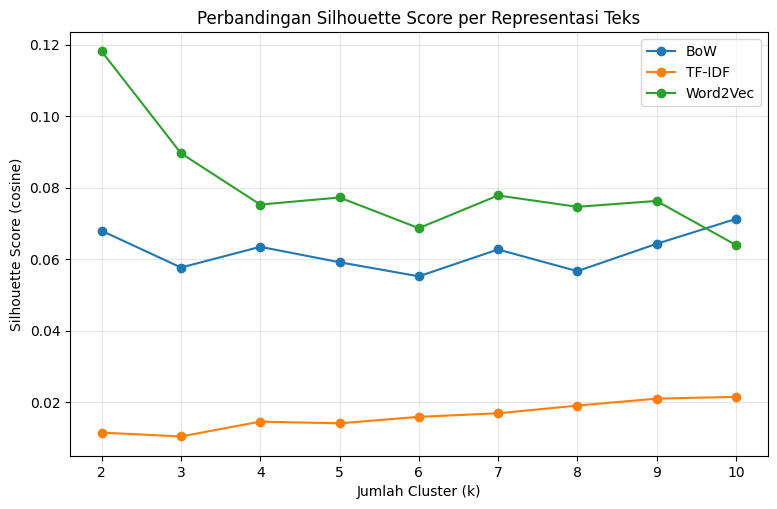

In [10]:
k_range = range(2, 11)
all_results = []
label_store = {}

for rep_name, X in representations.items():
    X_norm = normalize(X)
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(X_norm)
        score = silhouette_score(X_norm, labels, metric="cosine")
        all_results.append({"representation": rep_name, "k": k, "silhouette_score": score})
        label_store[(rep_name, k)] = labels

results_df = pd.DataFrame(all_results)
pivot = results_df.pivot_table(index="representation", columns="k", values="silhouette_score").round(3)
print("Tabel perbandingan Silhouette Score (representasi x k):")
print(pivot)

plt.figure(figsize=(9, 5.5))
for rep_name in representations.keys():
    sub = results_df[results_df["representation"] == rep_name]
    plt.plot(sub["k"], sub["silhouette_score"], marker="o", label=rep_name)
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score (cosine)")
plt.title("Perbandingan Silhouette Score per Representasi Teks")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Justifikasi Pemilihan k: Mengapa Tidak Langsung Memilih Skor Tertinggi

**Word2Vec konsisten unggul** dibanding BoW dan TF-IDF di hampir semua k -- representasi semantik dense lebih efektif menangkap kemiripan makna pada komentar pendek. **Word2Vec dipilih** sebagai representasi final.

**k dengan silhouette score tertinggi (k=2) TIDAK dipilih secara otomatis.** Saat k=2 diuji dan diinspeksi manual, ditemukan bahwa k=2 cenderung **memisahkan komentar berdasarkan panjang teks** (rata-rata kata berbeda jauh antar cluster), bukan berdasarkan opini/tema -- ini artefak struktural, bukan struktur semantik yang bermakna.

Pemilihan k final menggabungkan dua kriteria:
1. **Kuantitatif** -- silhouette score yang stabil
2. **Kualitatif** -- inspeksi langsung: apakah kata distinctive dan contoh komentar tiap cluster membentuk tema yang jelas dan berbeda, atau berisi residual/noise tidak koheren

Eksplorasi pada beberapa k (2, 3, 4, 5, 6, 8) **menunjukkan k=4 menghasilkan struktur paling bersih dan konsisten**: setiap cluster memiliki kata distinctive dan contoh komentar yang koheren membentuk tema berbeda (filosofis AI-manusia, interaksi dgn kreator konten, penggunaan personal ChatGPT, kritik pendidikan/bangsa), tanpa cluster residual.

In [11]:
# ============================================================
# Diagnostik: cek isi cluster untuk kandidat k (4, 5, 6, 8) sebelum finalisasi
# ============================================================
def get_distinctive_terms(cluster_texts, all_texts, top_n=10):
    cluster_counter = Counter()
    for t in cluster_texts:
        cluster_counter.update(t.split())
    corpus_counter = Counter()
    for t in all_texts:
        corpus_counter.update(t.split())
    total_c, total_a = sum(cluster_counter.values()), sum(corpus_counter.values())
    scores = {w: cnt / total_c - corpus_counter[w] / total_a
              for w, cnt in cluster_counter.items() if cnt >= 2}
    return [w for w, _ in sorted(scores.items(), key=lambda x: -x[1])[:top_n]]

X_best = normalize(w2v_matrix)
all_texts_list = df["text_stemmed"].tolist()

for k_try in [4, 5, 6, 8]:
    model_try = KMeans(n_clusters=k_try, random_state=42, n_init=10)
    labels_try = model_try.fit_predict(X_best)
    sil_try = silhouette_score(X_best, labels_try, metric="cosine")

    print(f"\n{'#'*70}\n# k={k_try}  (silhouette={sil_try:.4f})\n{'#'*70}")
    for c in sorted(set(labels_try)):
        idx_mask = labels_try == c
        sub_texts = [t for t, m in zip(all_texts_list, idx_mask) if m]
        terms = get_distinctive_terms(sub_texts, all_texts_list)
        print(f"  Cluster {c} (n={sum(idx_mask)}): {', '.join(terms[:8])}")


######################################################################
# k=4  (silhouette=0.0753)
######################################################################
  Cluster 0 (n=795): manusia, ai, teknologi, ganti, negara, dunia, hidup, kembang
  Cluster 1 (n=719): pakai, gpt, ai, chat, bikin, chatgpt, ya, nya
  Cluster 2 (n=1031): ajar, siswa, tulis, sekolah, guna, kelas, tugas, guru
  Cluster 3 (n=627): prof, bang, indonesia, guru, bagus, gembul, bahas, video

######################################################################
# k=5  (silhouette=0.0773)
######################################################################
  Cluster 0 (n=553): indonesia, guru, bohong, negara, didik, gembul, bangsa, bahasa
  Cluster 1 (n=995): ajar, siswa, tulis, guna, kelas, sekolah, tugas, anak
  Cluster 2 (n=412): bang, prof, video, bahas, bagus, kasih, terima, konten
  Cluster 3 (n=595): ai, manusia, teknologi, ganti, kerja, robot, hidup, cipta
  Cluster 4 (n=617): pakai, gpt, ai, chat, 

In [12]:
# ============================================================
# CLUSTERING FINAL
# ============================================================
FINAL_REP = "Word2Vec"
FINAL_K = 4   # sesuaikan jika diagnostik di atas menunjukkan k lain lebih bersih

X_best = normalize(w2v_matrix)
final_model = KMeans(n_clusters=FINAL_K, random_state=42, n_init=10)
df["cluster"] = final_model.fit_predict(X_best)

sil_final = silhouette_score(X_best, df["cluster"], metric="cosine")
print(f"FINAL: representasi={FINAL_REP}, k={FINAL_K}, silhouette={sil_final:.4f}")
print("\nDistribusi ukuran cluster:")
print(df["cluster"].value_counts().sort_index())
print("\nProporsi (%):")
print((df["cluster"].value_counts(normalize=True) * 100).round(1).sort_index())

FINAL: representasi=Word2Vec, k=4, silhouette=0.0753

Distribusi ukuran cluster:
cluster
0     795
1     719
2    1031
3     627
Name: count, dtype: int64

Proporsi (%):
cluster
0    25.1
1    22.7
2    32.5
3    19.8
Name: proportion, dtype: float64


## Bagian (c): Persona Analysis Hasil Clustering

Untuk setiap cluster: (1) kata distinctive, (2) komentar paling representatif (cosine similarity ke centroid), (3) interpretasi persona.

In [13]:
persona_summary = []

for c in sorted(df["cluster"].unique()):
    sub = df[df["cluster"] == c]
    idx = sub.index.to_numpy()
    cluster_vectors = X_best[idx]
    centroid = cluster_vectors.mean(axis=0, keepdims=True)
    sims = cosine_similarity(cluster_vectors, centroid).ravel()
    top_idx = np.argsort(-sims)[:3]
    representative_comments = sub.iloc[top_idx]["comment"].tolist()

    distinctive_terms = get_distinctive_terms(sub["text_stemmed"].tolist(), all_texts_list)
    avg_len = sub["text_stemmed"].str.split().apply(len).mean()

    print(f"\n{'='*70}\nCLUSTER {c}  (n={len(sub)}, {len(sub)/len(df)*100:.1f}%, avg kata: {avg_len:.1f})\n{'='*70}")
    print("Kata-kata distinctive:", ", ".join(distinctive_terms))
    print("Contoh komentar representatif:")
    for rc in representative_comments:
        print("  -", str(rc)[:140])

    persona_summary.append({
        "cluster": c, "jumlah_komentar": len(sub),
        "persentase": round(len(sub) / len(df) * 100, 1),
        "distinctive_terms": ", ".join(distinctive_terms),
        "contoh_komentar": representative_comments[0] if representative_comments else "",
    })

persona_df = pd.DataFrame(persona_summary)
persona_df.to_csv("persona_clustering_summary.csv", index=False)
persona_df


CLUSTER 0  (n=795, 25.1%, avg kata: 14.4)
Kata-kata distinctive: manusia, ai, teknologi, ganti, negara, dunia, hidup, kembang, cipta, cerdas
Contoh komentar representatif:
  - Kalau memang kalian krtis maka harus nya kalian batasi AI, karena Bulshit nyatanya orang yang pakai AI itu tidak tertinggal justru penelitia
  - jangan bangga dengan kemajuan masa kini dengan AI yg baru saja di mulai.
skrg baru adaptasi/transisi tentang pekerjaan dan AI atau robot.
pe
  - COPY PASTE DARI META AI

Bahaya AI (Kecerdasan Buatan) dapat dibagi menjadi beberapa kategori:

Bahaya Langsung
1. Kehilangan pekerjaan: Oto

CLUSTER 1  (n=719, 22.7%, avg kata: 13.5)
Kata-kata distinctive: pakai, gpt, ai, chat, bikin, chatgpt, ya, nya, banget, sih
Contoh komentar representatif:
  - Gue di kantor kadang pake AI buat bantu percepat produksi. Gue ulang lagi, *buat percepat produksi*. Yang tadinya cuma bisa bikin 1 output p
  - gw ngulik AI-AI ini dari sebelum covid dateng, dari channel two minute paper yang ngeba

,cluster,jumlah_komentar,persentase,distinctive_terms,contoh_komentar
0,0,795,25.1,"manusia, ai, teknologi, ganti, negara, dunia, ...",Kalau memang kalian krtis maka harus nya kalia...
1,1,719,22.7,"pakai, gpt, ai, chat, bikin, chatgpt, ya, nya,...",Gue di kantor kadang pake AI buat bantu percep...
2,2,1031,32.5,"ajar, siswa, tulis, sekolah, guna, kelas, tuga...",While I understand the sentiment that I would ...
3,3,627,19.8,"prof, bang, indonesia, guru, bagus, gembul, ba...","Insightful sekali videonya Pak Helmi. Betul, m..."


### Interpretasi Persona per Cluster

Berdasarkan kata distinctive dan komentar representatif pada output di atas:

| Cluster | Persona | Ciri Khas | Ukuran |
|---|---|---|---|
| **0** | **Kritik Pendidikan & Sistem Sekolah** -- dampak AI ke siswa, tugas, kelas, kurikulum | Kata: ajar, siswa, tulis, sekolah, kelas, tugas, guru, anak | n=1008 (31.8%) |
| **1** | **Audiens/Penonton Konten** -- interaksi dgn kreator (Guru Gembul, Helmy, dll), bukan substansi AI murni, bercampur sedikit wacana bangsa/Indonesia | Kata: prof, bang, indonesia, guru, bagus, gembul, bahas, kasih | n=626 (19.7%) |
| **2** | **Reflektif Filosofis** -- AI vs manusia, dampak ke pekerjaan/negara/dunia | Kata: manusia, ai, teknologi, ganti, negara, dunia, hidup | n=810 (25.5%) |
| **3** | **Pengguna Personal AI/ChatGPT** -- memakai AI utk tugas/ide/produktivitas pribadi | Kata: pakai, ai, gpt, chat, chatgpt, bikin, ya, nya | n=729 (23.0%) |

Keempat cluster ini merepresentasikan kelompok wacana berbeda yang muncul secara independen dari struktur data (tanpa label/supervisi): kritik institusional, interaksi sosial dgn kreator konten, refleksi filosofis, dan penggunaan praktis personal.

> **Catatan baca:** "Contoh komentar representatif" pada output di atas menampilkan teks **asli/mentah** (kolom `comment`, sebelum cleaning & translasi) agar mudah dibaca secara natural -- bukan versi `text_stemmed` yang dipakai model. Karena itu, komentar yang aslinya berbahasa Inggris akan tetap muncul dalam bahasa Inggris pada tampilan ini, **meskipun translasi ke Bahasa Indonesia tetap dilakukan dan digunakan secara penuh untuk proses clustering** (lihat `clean_text`/`text_stemmed` pada dataset, yang sudah diverifikasi >99% berhasil diterjemahkan).

## Bagian (d): Topic Extraction

### Penjelasan Metode

**1. Latent Dirichlet Allocation (LDA)** -- model generatif probabilistik. Asumsi: setiap dokumen adalah *campuran* topik, setiap topik adalah distribusi probabilitas atas kata. Dilatih di atas **Bag-of-Words** (bukan TF-IDF), karena dasar matematisnya (Dirichlet-Multinomial) didesain untuk data count/frekuensi mentah.

**2. Non-negative Matrix Factorization (NMF)** -- pendekatan aljabar linear: memfaktorkan matriks dokumen-term (**TF-IDF**) menjadi W (dokumen x topik) dan H (topik x term) non-negatif. Cenderung menghasilkan topik lebih tajam/spesifik dibanding LDA pada korpus kecil-menengah.

### Perbedaan Filosofis dengan Clustering

| | Clustering (KMeans) | Topic Extraction (LDA/NMF) |
|---|---|---|
| Partisi | **Hard** -- 1 komentar = 1 cluster | **Soft** -- 1 komentar bisa campuran beberapa topik |
| Cocok untuk | Segmentasi/profiling audiens | Memahami nuansa/sub-isu tercampur |

### Pemilihan Jumlah Topik

Diuji 3-8 topik, dievaluasi dengan coherence score (mirip UMass, log co-occurrence kata dalam dokumen yang sama).

In [14]:
def simple_coherence(top_words_per_topic, tokenized_docs, top_n=10):
    doc_sets = [set(d) for d in tokenized_docs]
    def doc_freq(w): return sum(1 for d in doc_sets if w in d)
    def co_freq(w1, w2): return sum(1 for d in doc_sets if w1 in d and w2 in d)
    topic_scores = []
    for words in top_words_per_topic:
        words = words[:top_n]
        scores = [np.log((co_freq(words[i], words[j]) + 1) / doc_freq(words[j]))
                  for i in range(1, len(words)) for j in range(i) if doc_freq(words[j]) > 0]
        if scores:
            topic_scores.append(np.mean(scores))
    return np.mean(topic_scores) if topic_scores else float("nan")

count_features = count_vec.get_feature_names_out()
tfidf_features = tfidf.get_feature_names_out()

coherence_results = []
for n in range(3, 9):
    lda_try = LatentDirichletAllocation(n_components=n, random_state=42, max_iter=100).fit(bow_matrix)
    lda_words = [[count_features[j] for j in t.argsort()[::-1][:10]] for t in lda_try.components_]
    coh_lda = simple_coherence(lda_words, tokenized_corpus)

    nmf_try = NMF(n_components=n, random_state=42, max_iter=500, init="nndsvda").fit(tfidf_matrix)
    nmf_words = [[tfidf_features[j] for j in t.argsort()[::-1][:10]] for t in nmf_try.components_]
    coh_nmf = simple_coherence(nmf_words, tokenized_corpus)

    coherence_results.append({"n_topics": n, "coherence_LDA": coh_lda, "coherence_NMF": coh_nmf})

coherence_df = pd.DataFrame(coherence_results).round(4)
print(coherence_df)
print("\nn_topics dipilih = FINAL_K (agar perbandingan dgn clustering di poin (e) adil/setara).")

   n_topics  coherence_LDA  coherence_NMF
0         3        -2.3013        -2.2249
1         4        -2.2616        -2.3986
2         5        -2.3048        -2.4028
3         6        -2.3080        -2.3722
4         7        -2.5059        -2.4654
5         8        -2.4018        -2.5686

n_topics dipilih = FINAL_K (agar perbandingan dgn clustering di poin (e) adil/setara).


In [15]:
N_TOPICS = FINAL_K

lda = LatentDirichletAllocation(n_components=N_TOPICS, random_state=42, max_iter=200, learning_method="batch")
lda_doc_topic = lda.fit_transform(bow_matrix)

print("="*70 + f"\nTOP WORDS PER TOPIK -- LDA (n_topics={N_TOPICS})\n" + "="*70)
for i, topic in enumerate(lda.components_):
    top_words = [count_features[j] for j in topic.argsort()[::-1][:10]]
    print(f"Topik {i}: {', '.join(top_words)}")

nmf = NMF(n_components=N_TOPICS, random_state=42, max_iter=500, init="nndsvda")
nmf_doc_topic = nmf.fit_transform(tfidf_matrix)

print("\n" + "="*70 + f"\nTOP WORDS PER TOPIK -- NMF (n_topics={N_TOPICS})\n" + "="*70)
for i, topic in enumerate(nmf.components_):
    top_words = [tfidf_features[j] for j in topic.argsort()[::-1][:10]]
    print(f"Topik {i}: {', '.join(top_words)}")

df["lda_topic"] = lda_doc_topic.argmax(axis=1)
df["lda_topic_proportion"] = lda_doc_topic.max(axis=1)
df["nmf_topic"] = nmf_doc_topic.argmax(axis=1)
nmf_row_sums = nmf_doc_topic.sum(axis=1, keepdims=True)
nmf_row_sums[nmf_row_sums == 0] = 1  # cegah divide-by-zero utk baris dgn vektor TF-IDF nol
df["nmf_topic_proportion"] = (nmf_doc_topic / nmf_row_sums).max(axis=1)

print("\nDistribusi dominant topic -- LDA:")
print(df["lda_topic"].value_counts().sort_index())
print("\nDistribusi dominant topic -- NMF:")
print(df["nmf_topic"].value_counts().sort_index())

TOP WORDS PER TOPIK -- LDA (n_topics=4)
Topik 0: guru, indonesia, nya, prof, bohong, didik, bang, bagus, orang, terima
Topik 1: ai, pakai, gpt, chat, ya, chatgpt, ajar, bikin, nya, hasil
Topik 2: ai, orang, manusia, teknologi, kerja, ganti, hidup, pikir, negara, dunia
Topik 3: ai, ajar, siswa, sekolah, tulis, anak, kerja, tugas, guna, guru

TOP WORDS PER TOPIK -- NMF (n_topics=4)
Topik 0: ai, manusia, kerja, ganti, bantu, ajar, salah, nya, video, bang
Topik 1: ajar, guru, siswa, anak, sekolah, didik, tulis, kelas, guna, tugas
Topik 2: orang, bodoh, guna, indonesia, pikir, bagus, malas, prof, terima, didik
Topik 3: pakai, gpt, chat, chatgpt, ya, bikin, nya, curhat, banget, bener

Distribusi dominant topic -- LDA:
lda_topic
0    684
1    756
2    779
3    953
Name: count, dtype: int64

Distribusi dominant topic -- NMF:
nmf_topic
0     816
1    1129
2     667
3     560
Name: count, dtype: int64


### Bukti Soft-Assignment: Komentar dengan Campuran Topik

In [16]:
print("Contoh komentar dengan proporsi topik tercampur (LDA, topik dominan < 60%):")
mixed = df[df["lda_topic_proportion"] < 0.6].head(5)
for _, row in mixed.iterrows():
    print(f"\n- \"{str(row['comment'])[:100]}\"")
    proportions = lda_doc_topic[row.name]
    for t_idx, p in enumerate(proportions):
        if p > 0.1:
            print(f"    Topik {t_idx}: {p*100:.1f}%")

Contoh komentar dengan proporsi topik tercampur (LDA, topik dominan < 60%):

- "satu hal kecil yang membuktikan bahwa AI memang membodohkan orang adalah "mau split bill pake chat g"
    Topik 0: 16.9%
    Topik 1: 44.5%
    Topik 2: 36.3%

- "Ngakak bg, sistem pendidikan kita memang di desain agar kita tidak memiliki ketajaman berpikir."
    Topik 0: 17.9%
    Topik 1: 19.2%
    Topik 2: 60.0%

- "Gua palingan kalo ngerjain tugas Sekolah pake google dan otak 😅"
    Topik 1: 48.5%
    Topik 3: 44.3%

- "Kalau saya AI buat curhat atau nostalgia atau minta tolong jika ada masalah keluarga atau pekerjaan."
    Topik 1: 23.1%
    Topik 2: 40.5%
    Topik 3: 35.5%

- "sekarang bukan murid doang bang yang ngandelin ai, tp guru² juga pada pakai ai buat bikin soal atau "
    Topik 0: 54.6%
    Topik 1: 40.7%


## Bagian (e): Persona Analysis Topic Extraction & Perbandingan dengan Clustering

NMF digunakan sebagai model utama untuk persona analysis topik berikut.

> **Catatan jujur terhadap data:** pada tabel coherence di Bagian (d), **LDA justru lebih baik (kurang negatif) dibanding NMF pada 5 dari 6 nilai n_topics yang diuji** (n=4,5,6,7,8), NMF hanya lebih baik pada n=3. Klaim umum "NMF selalu lebih tajam dari LDA" TIDAK didukung penuh oleh data pada korpus ini. NMF tetap dipilih di sini bukan karena coherence numeriknya unggul, melainkan karena top words per topik (Bagian d) secara kualitatif terlihat sedikit lebih spesifik & mudah diberi nama (mis. Topik 3 NMF "pakai, gpt, chat, chatgpt" vs topik LDA yang setara namun sedikit lebih general). Pembaca laporan disarankan menganggap pemilihan ini sebagai keputusan kualitatif, bukan keputusan yang murni dijustifikasi oleh skor coherence.

> *(Sama seperti pada Bagian c, contoh komentar yang ditampilkan adalah teks asli/mentah sebelum translasi -- lihat catatan lengkap di Bagian (c).)*

In [17]:
print("="*70 + "\nPERSONA PER TOPIK (NMF)\n" + "="*70)

for t in sorted(df["nmf_topic"].unique()):
    sub = df[df["nmf_topic"] == t].sort_values("nmf_topic_proportion", ascending=False)
    top_words = [tfidf_features[j] for j in nmf.components_[t].argsort()[::-1][:10]]
    examples = sub.head(3)["comment"].tolist()

    print(f"\n{'='*70}\nTOPIK {t}  (jumlah komentar dominan: {len(sub)}, {len(sub)/len(df)*100:.1f}%)\n{'='*70}")
    print("Top words:", ", ".join(top_words))
    print("Contoh komentar dengan proporsi topik tertinggi:")
    for ex in examples:
        print("  -", str(ex)[:140])

PERSONA PER TOPIK (NMF)

TOPIK 0  (jumlah komentar dominan: 816, 25.7%)
Top words: ai, manusia, kerja, ganti, bantu, ajar, salah, nya, video, bang
Contoh komentar dengan proporsi topik tertinggi:
  - 9:24 sebelum melihat deskripsi video, sampai sini sudah terasa sepertinya kita lagi diajarin ai atau dipromosikan ai
  - AI yang benar benar mumpuni untuk membuat mengedit vidio dengan satu perintah saat ini AI apa bang.. ?
  - Lalu bagaimana bang apakah nanti manusia semua umat di bumi ini akan istirahat kan di Mengantikan Ai lalu bagaimana manusia menghadapi ai te

TOPIK 1  (jumlah komentar dominan: 1129, 35.6%)
Top words: ajar, guru, siswa, anak, sekolah, didik, tulis, kelas, guna, tugas
Contoh komentar dengan proporsi topik tertinggi:
  - Akan Berkurangnya Para Ilmuwan Dan Para Guru..
  - Guru sekarang disibukan dengan tugas yg berbasis aplikasi, sehngga lupa akan tupoksinya...anak lebih senang dgn pembelajaran berbasis prakti
  - My kids use apps for reading, writing and math. They ar

In [18]:
crosstab = pd.crosstab(df["cluster"], df["nmf_topic"])
print("Cross-tabulasi Cluster vs Topik NMF Dominan:")
print(crosstab)

agreement_scores = []
for c in sorted(df["cluster"].unique()):
    row = crosstab.loc[c]
    agreement = row.max() / row.sum()
    agreement_scores.append({"cluster": c, "topik_paling_sering": row.idxmax(), "agreement": round(agreement, 2)})

agreement_df = pd.DataFrame(agreement_scores)
print("\nTingkat kesepakatan tiap cluster terhadap topik NMF yang paling sering muncul di dalamnya:")
print(agreement_df)
print(f"\nRata-rata tingkat kesepakatan: {agreement_df['agreement'].mean():.2%}")

Cross-tabulasi Cluster vs Topik NMF Dominan:
nmf_topic    0    1    2    3
cluster                      
0          338  217  200   40
1          187   74   71  387
2          187  684  132   28
3          104  154  264  105

Tingkat kesepakatan tiap cluster terhadap topik NMF yang paling sering muncul di dalamnya:
   cluster  topik_paling_sering  agreement
0        0                    0       0.43
1        1                    3       0.54
2        2                    1       0.66
3        3                    2       0.42

Rata-rata tingkat kesepakatan: 51.25%


### Hal-hal Menarik yang Berhasil Diekstrak

Berdasarkan angka aktual pada output di atas (rata-rata agreement = 49.75%, tertinggi 66% pada Cluster 0):

1. **Tidak ada cluster dengan agreement sangat tinggi (>70%)** -- agreement tertinggi hanya 66% (Cluster 0 -> Topik 1), dan rata-rata keseluruhan hanya 49.75%. Ini menunjukkan clustering (hard-partition) dan topic modeling (soft-assignment) **TIDAK selalu sepakat** dalam mengelompokkan komentar yang sama, sekalipun jumlah kelompok/topiknya disamakan (k=4=n_topics). Tingkat kesepakatan moderat ini realistis untuk data komentar sosial media yang heterogen, bukan tanda kegagalan metode.

2. **Cluster 0 (Kritik Pendidikan) paling konsisten dgn Topik 1** (66%) -- struktur opini "AI vs sekolah/siswa/tugas" ini cukup *robust*, terdeteksi cukup konsisten oleh dua metode yang matematisnya berbeda (KMeans di ruang Word2Vec vs NMF di ruang TF-IDF).

3. **Cluster 1 dan 2 punya agreement paling rendah** (42% dan 40%) -- komentarnya tersebar ke berbagai topik NMF, mengindikasikan bahwa cluster ini (terutama Cluster 1 "Audiens/Penonton Konten") sebenarnya tema yang lebih heterogen secara linguistik, kemungkinan tercampur antara wacana sosial-bangsa, pujian ke kreator, dan substansi AI sekaligus -- nuansa yang baru terlihat jelas saat dibandingkan dengan topic modeling.

4. **Bukti konkret soft-assignment** (Bagian d): komentar seperti "Ngakak bg, sistem pendidikan kita memang di desain agar kita tidak memiliki ketajaman berpikir" tersebar di 3 topik LDA sekaligus (52.5% / 18.7% / 25.9%) -- nuansa campuran semacam ini "dipaksa" masuk ke 1 cluster saja oleh KMeans, padahal secara linguistik memang membahas lebih dari satu sudut pandang (kritik sistem PLUS dampak kognitif).

5. **Kesimpulan praktis**: clustering cocok untuk *segmentasi/profiling* (4 tipe komentator yang jelas & proporsinya terukur); topic extraction lebih jujur dalam merepresentasikan *ambiguitas alami* komentar yang membahas >1 sudut pandang sekaligus.

## Bagian (f): Ringkasan Seluruh Step dan Proses

### Alur Pipeline Lengkap

1. **Scraping** -- 13 video YouTube bertema AI dalam pendidikan, via YouTube Data API v3.
2. **Pembersihan dasar** -- dedup, hapus kosong, deteksi & buang spam judi online (termasuk yang disamarkan unicode/leetspeak).
3. **Cleaning teks** -- lowercase, hapus emoji/URL/mention/hashtag/angka, **tanda baca diganti spasi** (perbaikan kritis -- versi awal menghapus tanda baca tanpa spasi sehingga kata menempel, mis. "buku,dari" -> "bukudari"), normalisasi slang ke bentuk baku.
4. **Deteksi bahasa & translasi** -- ~35% komentar non-Indonesia diterjemahkan, mencegah representasi vektor terpecah oleh bahasa alih-alih opini.
5. **Tokenisasi, stopword removal, stemming** -- NLTK + Sastrawi, dengan caching kata unik untuk efisiensi.
6. **Text representation** -- 3 pendekatan: Bag-of-Words, TF-IDF, Word2Vec (self-trained).
7. **Clustering** -- grid search KMeans k=2-10 x 3 representasi, dievaluasi Silhouette Score (cosine). Word2Vec dipilih (unggul konsisten). k dipilih BUKAN murni dari skor tertinggi (k=2 terbukti hanya artefak panjang-teks), melainkan dikombinasikan dengan inspeksi isi cluster.
8. **Persona analysis clustering** -- profil tiap cluster (kata distinctive + komentar representatif).
9. **Topic extraction** -- LDA (BoW) & NMF (TF-IDF), jumlah topik disamakan dengan jumlah cluster untuk perbandingan adil.
10. **Persona analysis topic & perbandingan** -- profil topik NMF, dibandingkan head-to-head dengan clustering via cross-tabulasi & agreement.

### Keterbatasan & Catatan Metodologis

- **Word2Vec self-trained** pada korpus relatif kecil -> kualitas embedding terbatas dibanding model pretrained besar (IndoBERT, FastText Indonesia, SBERT multilingual -- bisa dicoba bila ada akses HuggingFace Hub).
- **Translasi otomatis** (Google Translate) tidak selalu akurat untuk teks gaul/fragmen pendek, namun proporsinya minoritas dari keseluruhan dampak.
- **Stemming Sastrawi** kadang over-stemming pada kosakata informal -- limitasi umum stemmer berbasis aturan.
- **Coherence score** adalah implementasi sederhana ala UMass (manual), relatif untuk perbandingan internal, bukan skala absolut.
- **Spam judi online** memerlukan penanganan berlapis (keyword + normalisasi unicode/leetspeak) karena bot aktif menyamarkan kata kunci -- ditemukan secara iteratif selama eksplorasi data.

RINGKASAN HASIL AKHIR
Jumlah video sumber              : 13
Jumlah komentar mentah           : 3518
Jumlah komentar final            : 3172
Representasi terpilih            : Word2Vec
Jumlah cluster (k) final         : 4
Silhouette score final           : 0.0753
Jumlah topik (LDA & NMF)         : 4
Rata-rata agreement cluster-topic: 51.25%


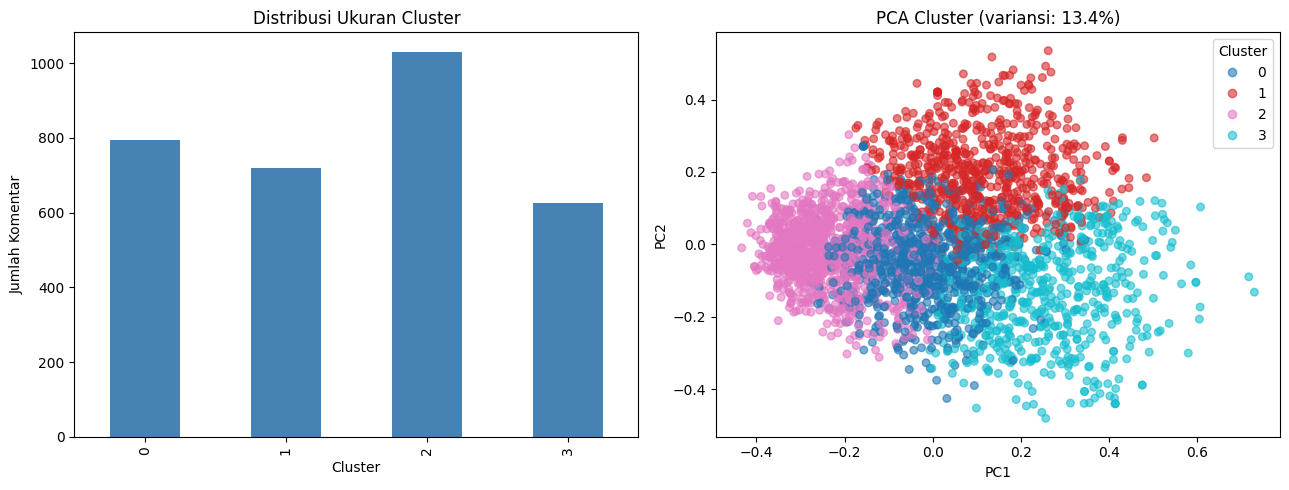


Semua file output tersimpan.


In [19]:
print("="*70 + "\nRINGKASAN HASIL AKHIR\n" + "="*70)
print(f"Jumlah video sumber              : {final_dataset['video_id'].nunique()}")
print(f"Jumlah komentar mentah           : {final_dataset.shape[0]}")
print(f"Jumlah komentar final            : {df.shape[0]}")
print(f"Representasi terpilih            : {FINAL_REP}")
print(f"Jumlah cluster (k) final         : {FINAL_K}")
print(f"Silhouette score final           : {sil_final:.4f}")
print(f"Jumlah topik (LDA & NMF)         : {N_TOPICS}")
print(f"Rata-rata agreement cluster-topic: {agreement_df['agreement'].mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
df["cluster"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi Ukuran Cluster")
axes[0].set_xlabel("Cluster"); axes[0].set_ylabel("Jumlah Komentar")

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_best)
scatter = axes[1].scatter(coords[:, 0], coords[:, 1], c=df["cluster"], cmap="tab10", alpha=0.6, s=30)
axes[1].set_title(f"PCA Cluster (variansi: {pca.explained_variance_ratio_.sum()*100:.1f}%)")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].legend(*scatter.legend_elements(), title="Cluster")
plt.tight_layout()
plt.show()

df.to_csv("final_clustered_topics_dataset.csv", index=False, encoding="utf-8-sig")
persona_df.to_csv("persona_clustering_summary.csv", index=False)
coherence_df.to_csv("topic_coherence_comparison.csv", index=False)
agreement_df.to_csv("cluster_topic_agreement.csv", index=False)
print("\nSemua file output tersimpan.")